<a href="https://colab.research.google.com/github/e-j223/IS4487/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [2]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset from Assignment 6
df = pd.read_csv('/content/cleaned_airbnb_data_6.csv')

# Check dimensions and available columns
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Preview the first five listings
df.head()

Dataset shape: (2535, 88)

Column names:
['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name', 'description', 'picture_url', 'host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_about', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood', 'host_listings_count', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights', 'maximum_night

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,...,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,review_scores_rating_missing
0,50904,https://www.airbnb.com/rooms/50904,20260629161552,2026-06-29,city scrape,Boutique room in Antwerp's fashion district,Welcome to a vintage-styled private room in a ...,https://a0.muscache.com/pictures/12996741/1ccb...,234077,https://www.airbnb.com/users/show/234077,...,5.00,5.00,NaN,NaN,25,18,5,0,0.02,False
1,345959,https://www.airbnb.com/rooms/345959,20260629161552,2026-06-29,city scrape,Marleen's home in Antwerp city,"your entire, private groundfloor 2-bedroom apa...",https://a0.muscache.com/pictures/11642662/f9b6...,1754396,https://www.airbnb.com/users/show/1754396,...,4.62,4.83,NaN,NaN,1,1,0,0,0.90,False
2,366252,https://www.airbnb.com/rooms/366252,20260629161552,2026-06-29,city scrape,ROOM IN FAMILY HOME near C. Station,"In the Antwerp district of Borgerhout, we live...",https://a0.muscache.com/pictures/airflow/Hosti...,1820186,https://www.airbnb.com/users/show/1820186,...,4.43,4.66,NaN,NaN,2,0,2,0,0.93,False
3,636664,https://www.airbnb.com/rooms/636664,20260629161552,2026-06-29,city scrape,"sunny rooftop apartment, sleeps 2-5",Centrally located two-bedroom rooftop apartmen...,https://a0.muscache.com/pictures/9944653/62c01...,462975,https://www.airbnb.com/users/show/462975,...,4.37,4.43,NaN,NaN,1,1,0,0,0.81,False
4,772842,https://www.airbnb.com/rooms/772842,20260629161552,2026-06-29,city scrape,Loftstyle App w/ Easy parking & amazing views,If you're looking for a special getaway walkin...,https://a0.muscache.com/pictures/hosting/Hosti...,4050173,https://www.airbnb.com/users/show/4050173,...,4.47,4.35,NaN,NaN,1,1,0,0,0.51,False


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

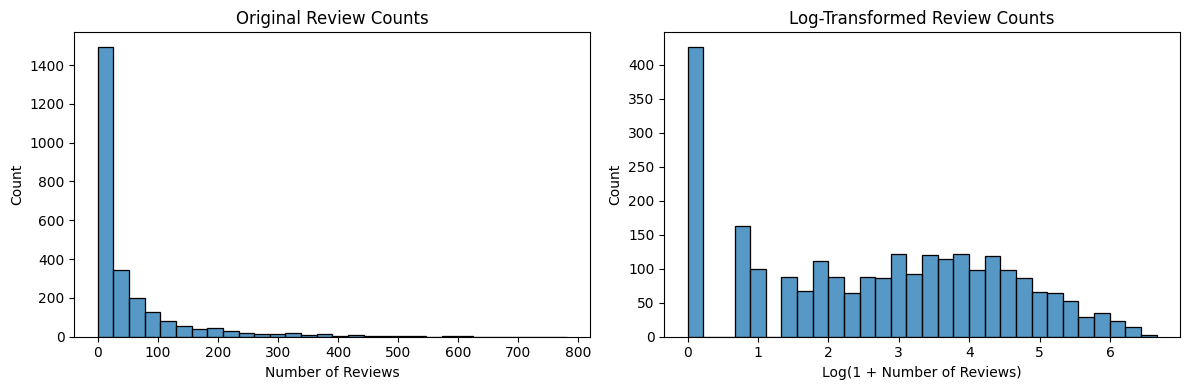

Original skewness: 3.1278066212295266
Transformed skewness: -0.04059706182347123


In [3]:
# Add code here 🔧
# Log-transform review counts, including zeros
df['number_of_reviews_log'] = np.log1p(df['number_of_reviews'])

# Compare original and transformed distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x='number_of_reviews', bins=30, ax=axes[0])
axes[0].set_title('Original Review Counts')
axes[0].set_xlabel('Number of Reviews')

sns.histplot(data=df, x='number_of_reviews_log', bins=30, ax=axes[1])
axes[1].set_title('Log-Transformed Review Counts')
axes[1].set_xlabel('Log(1 + Number of Reviews)')

plt.tight_layout()
plt.show()

# Compare skewness before and after
print("Original skewness:", df['number_of_reviews'].skew())
print("Transformed skewness:", df['number_of_reviews_log'].skew())

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined number_of_reviews. Its skewness was about 3.13, indicating a strong right skew.


2. I used np.log1p(), which calculates log(1 + number_of_reviews). This compresses large review counts and includes listings with zero reviews.


3. Skewness decreased to about -0.04, making the distribution much more symmetric. This makes patterns easier to visualize and reduces the influence of extremely high review counts when using the transformed variable in analysis.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale review counts to 0–1
minmax_scaler = MinMaxScaler()
df['number_of_reviews_scaled'] = minmax_scaler.fit_transform(
    df[['number_of_reviews']]
).ravel()

# Standardize minimum nights using Z-scores
standard_scaler = StandardScaler()
df['minimum_nights_standardized'] = standard_scaler.fit_transform(
    df[['minimum_nights']]
).ravel()

# Compare original and transformed columns
df[
    [
        'number_of_reviews',
        'number_of_reviews_scaled',
        'minimum_nights',
        'minimum_nights_standardized'
    ]
].describe()


,number_of_reviews,number_of_reviews_scaled,minimum_nights,minimum_nights_standardized
count,2535.000000,2535.000000,2535.000000,2.535000e+03
mean,51.516765,0.065963,6.860750,1.962051e-17
std,88.823742,0.113731,23.741902,1.000197e+00
min,0.000000,0.000000,1.000000,-2.469013e-01
25%,2.000000,0.002561,1.000000,-2.469013e-01
50%,16.000000,0.020487,1.000000,-2.469013e-01
75%,59.500000,0.076184,2.000000,-2.047733e-01
max,781.000000,1.000000,500.000000,2.077494e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I applied Min-Max scaling to number_of_reviews and Z-score standardization to minimum_nights. I added both transformed versions as new columns.

2. These values are useful in models that are sensitive to scale. Review counts now range from 0 to 1, while minimum nights is expressed relative to its mean in standard deviation units.

3. Airbnb data analysts could use these columns when comparing or clustering listings. Scaling helps prevent a variable from dominating distance calculations simply because its original numbers are larger.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [5]:
# Add code here 🔧
# Group listings by review volume
df['review_volume_group'] = pd.cut(
    df['number_of_reviews'],
    bins=[-1, 10, 50, np.inf],
    labels=['Low', 'Medium', 'High']
)

# Show the number of listings in each group
print(df['review_volume_group'].value_counts(sort=False))

# Preview original counts and their groups
df[['number_of_reviews', 'review_volume_group']].head()

review_volume_group
Low       1106
Medium     715
High       714
Name: count, dtype: int64


,number_of_reviews,review_volume_group
0,3,Low
1,154,High
2,161,High
3,136,High
4,83,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped number_of_reviews into three categories: Low for 0–10 reviews, Medium for 11–50, and High for 51 or more.


2. The grouped view makes it easier to compare listings by review volume without focusing on every individual count. It also gives a dashboard simple categories to display.

3. Airbnb’s marketing team could use these groups to identify listings with few reviews that may need more visibility and tailor campaigns to different levels of review activity.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [6]:
# Add code here 🔧
# Review count relative to the host's number of listings in this city
df['reviews_per_host_listing'] = (
    df['number_of_reviews']
    / df['calculated_host_listings_count'].replace(0, np.nan)
)

# Flag listings requiring stays of at least 30 nights
df['long_term_stay_required'] = (
    df['minimum_nights'] >= 30
).astype(int)

# Preview the inputs and new variables
df[
    [
        'number_of_reviews',
        'calculated_host_listings_count',
        'reviews_per_host_listing',
        'minimum_nights',
        'long_term_stay_required'
    ]
].head()

,number_of_reviews,calculated_host_listings_count,reviews_per_host_listing,minimum_nights,long_term_stay_required
0,3,25,0.12,1,0
1,154,1,154.00,2,0
2,161,2,80.50,1,0
3,136,1,136.00,2,0
4,83,1,83.00,30,1


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created reviews_per_host_listing by dividing each listing’s review count by the host’s listing count in Antwerp. It shows review activity for that listing relative to the size of the host’s local portfolio. I also created long_term_stay_required to flag listings requiring at least 30 nights.

2. Airbnb analysts could use the review ratio when exploring differences between hosts with small and large portfolios. Guests and marketing teams could use the long-term flag.

3. The ratio provides another way to compare review activity, although it is not the host’s average reviews across all properties. The flag helps identify listings suitable for guests seeking extended stays.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [7]:
# Add code here 🔧
# Create a 0/1 indicator column for each room type
room_type_encoded = pd.get_dummies(
    df['room_type'],
    prefix='room_type',
    dtype=int
)

# Add the encoded columns to the dataframe
df[room_type_encoded.columns] = room_type_encoded

# Preview room types and their indicators
df[['room_type'] + room_type_encoded.columns.tolist()].head()

,room_type,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,Hotel room,0,1,0,0
1,Entire home/apt,1,0,0,0
2,Private room,0,0,1,0
3,Entire home/apt,1,0,0,0
4,Entire home/apt,1,0,0,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded room_type because it describes an important difference between listings, such as an entire home versus a private room.
2. I used one-hot encoding because room types do not have a natural ranking. Each category gets its own column containing 0 or 1.
3. These indicators let a pricing model use room type as a predictor without assuming an artificial order between categories. They also make it easy to filter and compare room types in dashboards and reports.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [9]:
# export csv here 🔧
# Remove columns that contain no usable values
df = df.dropna(axis=1, how='all')

# Export the transformed dataset
df.to_csv('/content/cleaned_airbnb_data_7.csv', index=False)

print("Exported: cleaned_airbnb_data_7.csv")
print("Final dataset shape:", df.shape)

Exported: cleaned_airbnb_data_7.csv
Final dataset shape: (2535, 87)


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. The log transformation was the most interesting step. Review counts started with a strong right skew of about 3.13. After the transformation, skewness was about -0.04, making the distribution much more symmetric and easier to visualize.

2. The review-volume groups and long-term-stay flag would be useful to hosts and analysts. They make it easier to compare review activity and identify listings that require extended stays.

3. I would build a dashboard showing review volume, room type, and minimum-stay requirements. Users could filter listings and compare patterns across neighborhoods.

4. This connects to my learning outcomes about predictive modeling and visualization. Scaling and encoding prepare variables for models, while transformations and grouping make patterns easier to display. Similar techniques could help me analyze investment data, with care to explain how transformations affect interpretation.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"